# Evaluating a structural causal model

A structural causal model assigns one autonomous equation to every variable:

$$
X_j=f_j\!\left(\operatorname{pa}_j,U_j\right),
\qquad j=1,\ldots,p.
$$

Here, $X_j$ is variable $j$, $f_j$ is its supplied structural mechanism, $\operatorname{pa}_j$ is the vector of parent values entering that mechanism, $U_j$ is its outside input, and $p$ is the number of variables.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("03_structural_treatment_effects");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
include(joinpath("..","support","BookTreatmentStudy.jl"))
using .BookTreatmentStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter03_random_inputs")
function table(values,name,caption)
    shown = copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter25-"*replace(name,"_"=>"-"))
    return nothing
end
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end;


## First 50 evaluated samples

Row,Node,Parents in lexical order,Equation
,String,String,String
1,X,None,X = U_X
2,M,X,M = 0.8 X + U_M
3,Y,"M, X",Y = 0.7 M + 0.4 X + U_Y


Row,Node,Mean,Standard deviation,Minimum,Maximum
,String,Float64,Float64,Float64,Float64
1,X,0.0926104,0.968548,-2.54464,2.84681
2,M,0.0635158,0.983941,-2.62941,3.53367
3,Y,0.0721905,1.21315,-3.21494,3.1801


Row,Check,Observed,Passed
,String,Any,String
1,Canonical node order,"X, M, Y",Yes
2,Hand and public values agree,0.0,Yes
3,Constructor isolates supplied values,true,Yes


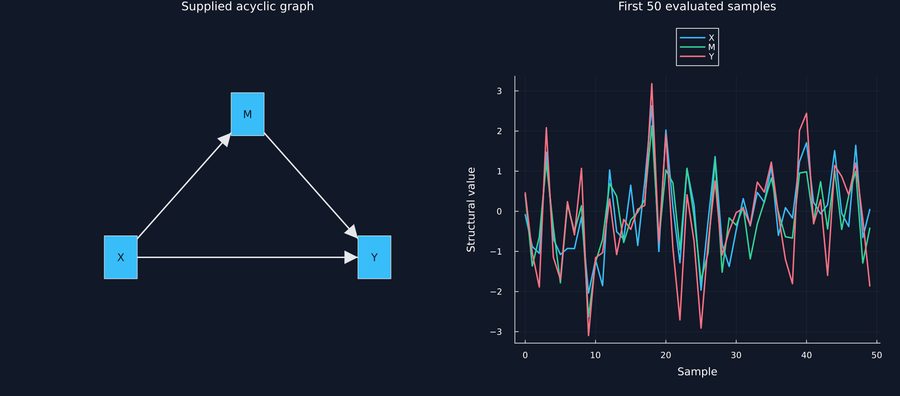

In [1]:
store = PrimitiveStore(input_directory,"scm")
sample_size = 500
chain_dag = CausalDAG(["M","X","Y"],[("X","M"),("M","Y"),("X","Y")],["M","X","Y"])
chain_inputs = normal_block(store,"chain")
chain_exogenous = Dict("X"=>chain_inputs[:,1],"M"=>.6 .*chain_inputs[:,2],"Y"=>.7 .*chain_inputs[:,3])
chain_mechanisms = Dict("X"=>((parents,noise)->noise),"M"=>((parents,noise)->.8 .*parents[:,1]+noise),"Y"=>((parents,noise)->.7 .*parents[:,1]+.4 .*parents[:,2]+noise))
chain_result = evaluate_structural_causal_model(chain_dag,chain_mechanisms,chain_exogenous)
chain_frame = DataFrame(Matrix(chain_result.values),collect(chain_result.node_order))
manual_x = chain_exogenous["X"]
manual_m = .8 .*manual_x+chain_exogenous["M"]
manual_y = .7 .*manual_m+.4 .*manual_x+chain_exogenous["Y"]
manual_values = hcat(manual_x,manual_m,manual_y)
chain_specification = frame(["Node","Parents in lexical order","Equation"],[["X","None","X = U_X"],["M","X","M = 0.8 X + U_M"],["Y","M, X","Y = 0.7 M + 0.4 X + U_Y"]])
chain_summary = structural_summary(chain_frame)
constructor_input = copy(manual_values)
constructor_result = StructuralCausalModelResult(("X","M","Y"),constructor_input)
constructor_input[1,1] += 1.0
constructor_isolation = constructor_result.values[1,1] == manual_values[1,1]
chain_check = frame(["Check","Observed","Passed"],[("Canonical node order",join(chain_result.node_order,", "),chain_result.node_order==("X","M","Y")),("Hand and public values agree",maximum(abs,chain_result.values-manual_values),chain_result.values≈manual_values),("Constructor isolates supplied values",string(constructor_isolation),constructor_isolation)])
table(chain_specification,"scm_chain_specification","Structural equations and lexical parent order for the three-node model.")
table(chain_summary,"scm_chain_summary","Summary of values produced by the structural equations.")
table(chain_check,"scm_chain_checks","Hand calculation, order, and protection checks.")
save_data(chain_frame,paths,"scm_chain_values")
positions = Dict("X"=>(0.,0.),"M"=>(1.2,.7),"Y"=>(2.4,0.))
graph_plot = identification_graph_panel(DirectedGraph(chain_dag.nodes,chain_dag.directed_edges),positions,"Supplied acyclic graph")
value_plot = plot(;xlabel="Sample",ylabel="Structural value",title="First 50 evaluated samples",legend=:outertop)
for (name,color) in [("X",palette.cyan),("M",palette.green),("Y",palette.rose)]
    plot!(value_plot,0:49,chain_frame[1:50,name];color,label=name)
end
save_figure(plot(graph_plot,value_plot;layout=(1,2),size=(1250,550)),paths,"scm_chain_graph_and_values")


## Order is determined by the graph

For every arrow $X_k\to X_j$, evaluation must respect the order condition:

$$
\operatorname{ord}(X_k)<\operatorname{ord}(X_j).
$$

Here, $X_k$ is a parent, $X_j$ is its child, and $\operatorname{ord}(X)$ is the position at which a node is evaluated; lexical order resolves ties among nodes that are simultaneously ready.

Row,Position,Node
,Int64,String
1,1,A
2,2,B
3,3,C
4,4,D


Row,Parent A,Parent B,D result
,Float64,Float64,Float64
1,1.0,20.0,201.0
2,2.0,21.0,212.0


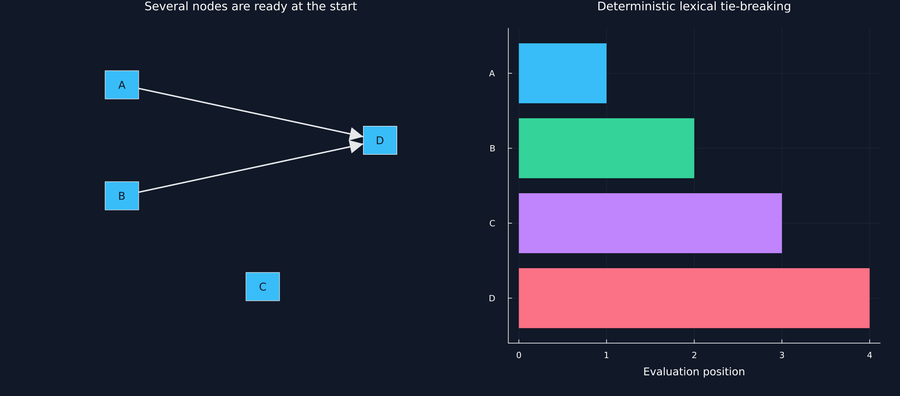

In [2]:
lexical_dag = CausalDAG(["D","C","B","A"],[("B","D"),("A","D")],["D","C","B","A"])
captured_parents = Matrix{Float64}[]
captured_parent_snapshots = Bool[]
function d_mechanism(parents,noise)
    push!(captured_parents,Matrix(parents))
    push!(captured_parent_snapshots,parents isa Matrix{Float64})
    return parents[:,1]+10.0 .*parents[:,2]+noise
end
lexical_result = evaluate_structural_causal_model(lexical_dag,Dict("D"=>d_mechanism,"C"=>((parents,noise)->noise),"B"=>((parents,noise)->noise),"A"=>((parents,noise)->noise)),Dict("D"=>[0.,0.],"C"=>[30.,31.],"B"=>[20.,21.],"A"=>[1.,2.]))
lexical_values = DataFrame(Matrix(lexical_result.values),collect(lexical_result.node_order))
lexical_order_table = DataFrame("Position"=>collect(1:length(lexical_result.node_order)),"Node"=>collect(lexical_result.node_order))
parent_order_table = DataFrame(captured_parents[1],["Parent A","Parent B"])
parent_order_table[!,"D result"] = lexical_values.D
table(lexical_order_table,"scm_lexical_order","Lexically resolved topological order.")
table(parent_order_table,"scm_parent_order","Parent columns supplied to the mechanism for D.")
save_data(lexical_values,paths,"scm_lexical_values")
positions = Dict("A"=>(0.,1.),"B"=>(0.,-.1),"C"=>(1.2,-1.),"D"=>(2.2,.45))
graph_plot = identification_graph_panel(DirectedGraph(lexical_dag.nodes,lexical_dag.directed_edges),positions,"Several nodes are ready at the start")
order_plot = bar(1:4,lexical_order_table.Position;orientation=:horizontal,yflip=true,color=[palette.cyan,palette.green,violet,palette.rose],linealpha=0,yticks=(1:4,lexical_order_table.Node),ylims=(.4,4.6),xlabel="Evaluation position",title="Deterministic lexical tie-breaking",legend=false)
save_figure(plot(graph_plot,order_plot;layout=(1,2),size=(1250,550)),paths,"scm_lexical_order")


## Intervention replaces one mechanism

Setting $X$ to a fixed value replaces its structural equation and leaves the remaining equations unchanged:

$$
\mathcal M_{\operatorname{do}(X=x)}
=\left\{X:=x,\ M:=0.8X+U_M,\ Y:=0.7M+0.4X+U_Y\right\}.
$$

Here, $\mathcal M_{\operatorname{do}(X=x)}$ is the intervened model, $x$ is the imposed treatment value, $M$ is the mediator, $Y$ is the outcome, and $U_M$ and $U_Y$ are the unchanged outside inputs.

Row,Variable,Mean under do(X=0),Mean under do(X=1),Mean difference
,String,Float64,Float64,Float64
1,X,0.0,1.0,1.0
2,M,-0.0105725,0.789427,0.8
3,Y,-0.0167155,0.943284,0.96


Row,Path,Effect
,String,Float64
1,Direct X to Y,0.4
2,Mediated X to M to Y,0.56
3,Total,0.96
4,Evaluated mean difference,0.96


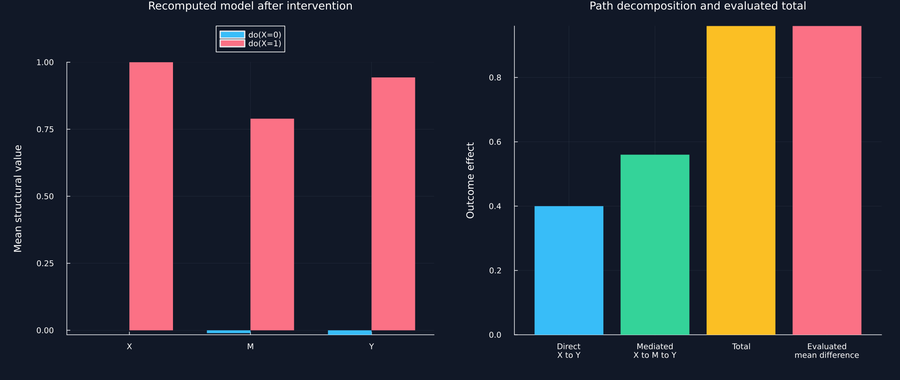

In [3]:
function intervened_result(level)
    mechanisms = copy(chain_mechanisms)
    mechanisms["X"] = (parents,noise)->fill(level,size(noise))
    return evaluate_structural_causal_model(chain_dag,mechanisms,chain_exogenous)
end
control_result,treated_result = intervened_result(0.),intervened_result(1.)
control_frame = DataFrame(Matrix(control_result.values),collect(control_result.node_order))
treated_frame = DataFrame(Matrix(treated_result.values),collect(treated_result.node_order))
outcome_effects = treated_frame.Y-control_frame.Y
mediator_effects = treated_frame.M-control_frame.M
intervention_summary = frame(["Variable","Mean under do(X=0)","Mean under do(X=1)","Mean difference"],[(name,mean(control_frame[!,name]),mean(treated_frame[!,name]),name=="M" ? mean(mediator_effects) : name=="Y" ? mean(outcome_effects) : mean(treated_frame.X)-mean(control_frame.X)) for name in ["X","M","Y"]])
path_effects = frame(["Path","Effect"],[("Direct X to Y",.4),("Mediated X to M to Y",.8*.7),("Total",.4+.8*.7),("Evaluated mean difference",mean(outcome_effects))])
table(intervention_summary,"scm_intervention_summary","Structural values under two interventions.")
table(path_effects,"scm_path_effects","Direct, mediated, total, and evaluated effects.")
save_data(control_frame,paths,"scm_control_values")
save_data(treated_frame,paths,"scm_treated_values")
mean_plot = bar((1:3).- .18,intervention_summary[!,"Mean under do(X=0)"];bar_width=.36,color=palette.cyan,linealpha=0,label="do(X=0)",xticks=(1:3,intervention_summary.Variable),ylabel="Mean structural value",title="Recomputed model after intervention",legend=:outertop)
bar!(mean_plot,(1:3).+ .18,intervention_summary[!,"Mean under do(X=1)"];bar_width=.36,color=palette.rose,linealpha=0,label="do(X=1)")
effect_plot = bar(1:4,path_effects.Effect;color=[palette.cyan,palette.green,palette.amber,palette.rose],linealpha=0,xticks=(1:4,["Direct\nX to Y","Mediated\nX to M to Y","Total","Evaluated\nmean difference"]),ylabel="Outcome effect",title="Path decomposition and evaluated total",legend=false)
save_figure(plot(mean_plot,effect_plot;layout=(1,2),size=(1350,570)),paths,"scm_intervention_effects")


## Intervening in a nonlinear causal fork

A nonlinear three-node model can be written as:

$$
A=U_A,
\qquad
B=\sin(A)+U_B,
\qquad
C=AB+U_C.
$$

Here, $A$, $B$, and $C$ are endogenous variables, $U_A$, $U_B$, and $U_C$ are their outside inputs, $\sin$ is the sine function, and the product $AB$ makes the outcome mechanism nonlinear in its two parents.

Row,Node,Mean,Standard deviation,Minimum,Maximum
,String,Float64,Float64,Float64,Float64
1,A,3.61615e-17,1.73577,-3.0,3.0
2,B,0.00433269,0.744644,-1.46397,1.46114
3,C,1.03892,0.742417,-0.845172,3.02567


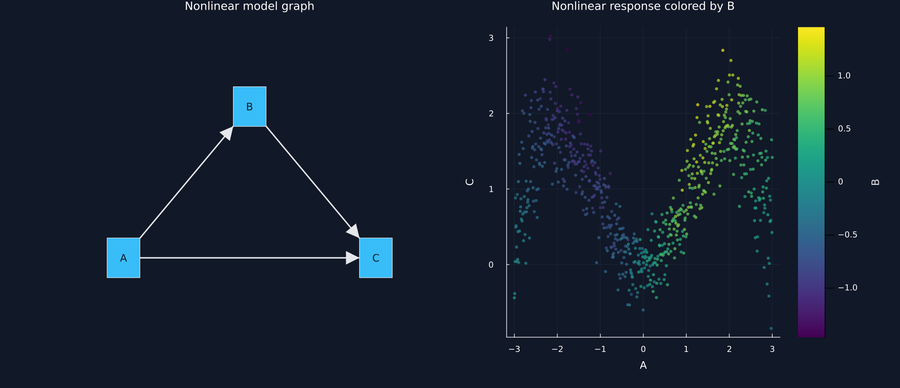

Row,Quantity,Value
,String,Float64
1,Correlation C and X,0.677965
2,Correlation C and Y,0.729628
3,Unadjusted X coefficient,0.882049
4,C-adjusted X coefficient,0.507154
5,Known direct X effect,0.5


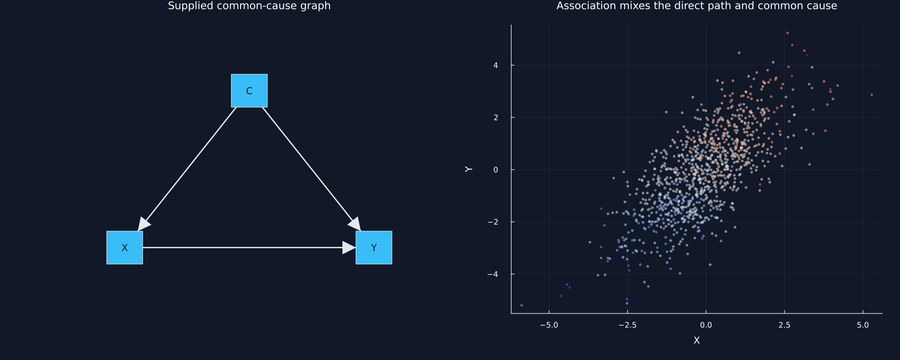

In [4]:
nonlinear_dag = CausalDAG(["A","B","C"],[("A","B"),("A","C"),("B","C")],["A","B","C"])
nonlinear_inputs = normal_block(store,"nonlinear")
nonlinear_exogenous = Dict("A"=>collect(range(-3.,3.;length=700)),"B"=>.18 .*nonlinear_inputs[:,1],"C"=>.25 .*nonlinear_inputs[:,2])
nonlinear_result = evaluate_structural_causal_model(nonlinear_dag,Dict("A"=>((parents,noise)->noise),"B"=>((parents,noise)->sin.(parents[:,1])+noise),"C"=>((parents,noise)->parents[:,1].*parents[:,2]+noise)),nonlinear_exogenous)
nonlinear_frame = DataFrame(Matrix(nonlinear_result.values),collect(nonlinear_result.node_order))
nonlinear_summary = structural_summary(nonlinear_frame)
table(nonlinear_summary,"scm_nonlinear_summary","Summary of the nonlinear structural model.")
save_data(nonlinear_frame,paths,"scm_nonlinear_values")
graph_plot = identification_graph_panel(DirectedGraph(nonlinear_dag.nodes,nonlinear_dag.directed_edges),Dict("A"=>(0.,0.),"B"=>(1.1,.8),"C"=>(2.2,0.)),"Nonlinear model graph")
response_plot = scatter(nonlinear_frame.A,nonlinear_frame.C;marker_z=nonlinear_frame.B,color=:viridis,markersize=2.5,markeralpha=.7,markerstrokewidth=0,colorbar_title="B",xlabel="A",ylabel="C",title="Nonlinear response colored by B",label="")
save_figure(plot(graph_plot,response_plot;layout=(1,2),size=(1300,560)),paths,"scm_nonlinear_graph_and_response")
fork_dag = CausalDAG(["C","X","Y"],[("C","X"),("C","Y"),("X","Y")],["C","X","Y"])
fork_innovations = normal_block(store,"fork")
fork_inputs = Dict("C"=>fork_innovations[:,1],"X"=>fork_innovations[:,2],"Y"=>fork_innovations[:,3])
fork_result = evaluate_structural_causal_model(fork_dag,Dict("C"=>((parents,noise)->noise),"X"=>((parents,noise)->.9 .*parents[:,1]+noise),"Y"=>((parents,noise)->.7 .*parents[:,1]+.5 .*parents[:,2]+noise)),fork_inputs)
fork_frame = DataFrame(Matrix(fork_result.values),collect(fork_result.node_order))
fork_relationships = frame(["Quantity","Value"],[("Correlation C and X",cor(fork_frame.C,fork_frame.X)),("Correlation C and Y",cor(fork_frame.C,fork_frame.Y)),("Unadjusted X coefficient",ols_slope(fork_frame.Y,fork_frame.X)),("C-adjusted X coefficient",ols_slope(fork_frame.Y,fork_frame.X,fork_frame.C)),("Known direct X effect",.5)])
table(fork_relationships,"scm_fork_relationships","Relationships and treatment coefficients in a supplied fork model.")
save_data(fork_frame,paths,"scm_fork_values")
graph_plot = identification_graph_panel(DirectedGraph(fork_dag.nodes,fork_dag.directed_edges),Dict("C"=>(.9,1.),"X"=>(0.,0.),"Y"=>(1.8,0.)),"Supplied common-cause graph")
association_plot = scatter(fork_frame.X,fork_frame.Y;marker_z=fork_frame.C,color=:coolwarm,markersize=2.3,markeralpha=.58,markerstrokewidth=0,colorbar=false,xlabel="X",ylabel="Y",title="Association mixes the direct path and common cause",label="")
save_figure(plot(graph_plot,association_plot;layout=(1,2),size=(1400,560)),paths,"scm_fork_graph_and_association")


## Protecting supplied inputs while rejecting invalid cases

In [5]:
snapshot_observations = Tuple[]
function snapshot_root(parents,noise)
    push!(snapshot_observations,(string(size(parents)),parents isa Matrix{Float64},noise isa Vector{Float64}))
    noise[1] = 7.0
    return noise
end
snapshot_dag = CausalDAG(["X"],Tuple{String,String}[],["X"])
source_values = [1.,2.]
snapshot_result = evaluate_structural_causal_model(snapshot_dag,Dict("X"=>snapshot_root),Dict("X"=>source_values))
source_isolated_during_evaluation = source_values == [1.,2.]
source_values .= 10.
snapshot_table = frame(["Parent shape","Parent snapshot","Outside input snapshot"],snapshot_observations)
snapshot_table[!,"Source isolated during evaluation"] .= source_isolated_during_evaluation
snapshot_table[!,"Result isolated from later source mutation"] .= snapshot_result.values == reshape([7.,2.],2,1)
table(snapshot_table,"scm_protection_checks","Independent mechanism snapshots and stored results.")
one_node = CausalDAG(["X"],Tuple{String,String}[],["X"])
two_nodes = CausalDAG(["X","Y"],[("X","Y")],["X","Y"])
identity_mechanism = (parents,noise)->noise
failure_checks = frame(["Check","Expected result","Observed result","Passed"],[contract_result("Wrong graph type",()->evaluate_structural_causal_model("X",Dict("X"=>identity_mechanism),Dict("X"=>[1.])),ArgumentError),contract_result("Mechanisms not a mapping",()->evaluate_structural_causal_model(one_node,(),Dict("X"=>[1.])),ArgumentError),contract_result("Missing mechanism",()->evaluate_structural_causal_model(one_node,Dict(),Dict("X"=>[1.])),ArgumentError),contract_result("Noncallable mechanism",()->evaluate_structural_causal_model(one_node,Dict("X"=>1),Dict("X"=>[1.])),ArgumentError),contract_result("Empty outside input",()->evaluate_structural_causal_model(one_node,Dict("X"=>identity_mechanism),Dict("X"=>Float64[])),ArgumentError),contract_result("Two-dimensional outside input",()->evaluate_structural_causal_model(one_node,Dict("X"=>identity_mechanism),Dict("X"=>reshape([1.],1,1))),ArgumentError),contract_result("Boolean outside input",()->evaluate_structural_causal_model(one_node,Dict("X"=>identity_mechanism),Dict("X"=>[true])),ArgumentError),contract_result("Nonfinite outside input",()->evaluate_structural_causal_model(one_node,Dict("X"=>identity_mechanism),Dict("X"=>[Inf])),ArgumentError),contract_result("Unequal outside-input lengths",()->evaluate_structural_causal_model(two_nodes,Dict("X"=>identity_mechanism,"Y"=>identity_mechanism),Dict("X"=>[1.],"Y"=>[1.,2.])),ArgumentError),contract_result("Scalar mechanism result",()->evaluate_structural_causal_model(one_node,Dict("X"=>((parents,noise)->1.)),Dict("X"=>[0.])),ArgumentError),contract_result("Wrong-length mechanism result",()->evaluate_structural_causal_model(one_node,Dict("X"=>((parents,noise)->[1.,2.])),Dict("X"=>[0.])),ArgumentError),contract_result("Nonfinite mechanism result",()->evaluate_structural_causal_model(one_node,Dict("X"=>((parents,noise)->[NaN])),Dict("X"=>[0.])),ArgumentError),contract_result("Cyclic graph declaration",()->CausalDAG(["X","Y"],[("X","Y"),("Y","X")],["X","Y"]),ArgumentError),contract_result("Mechanism failure passes through",()->evaluate_structural_causal_model(one_node,Dict("X"=>((parents,noise)->error("mechanism failed"))),Dict("X"=>[0.])),ErrorException)])
scm_summary = frame(["Question","Answer"],[["Who supplies the graph?","The caller"],["Who supplies the mechanisms?","The caller"],["Does evaluation discover a graph?","No"],["What makes the result repeatable?","Fixed inputs, mechanisms, and lexical order"],["How is an intervention represented?","Replace one mechanism and recompute descendants"]])
table(failure_checks,"scm_failure_checks","Boundary and failure checks for deterministic structural evaluation.")
table(scm_summary,"scm_section_summary","Main conclusions from the structural-model experiments.")


Row,Parent shape,Parent snapshot,Outside input snapshot,Source isolated during evaluation,Result isolated from later source mutation
,String,String,String,String,String
1,"(2, 0)",Yes,Yes,Yes,Yes


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Wrong graph type,Rejected,Rejected,Yes
2,Mechanisms not a mapping,Rejected,Rejected,Yes
3,Missing mechanism,Rejected,Rejected,Yes
4,Noncallable mechanism,Rejected,Rejected,Yes
5,Empty outside input,Rejected,Rejected,Yes
6,Two-dimensional outside input,Rejected,Rejected,Yes
7,Boolean outside input,Rejected,Rejected,Yes
8,Nonfinite outside input,Rejected,Rejected,Yes
9,Unequal outside-input lengths,Rejected,Rejected,Yes


Row,Question,Answer
,String,String
1,Who supplies the graph?,The caller
2,Who supplies the mechanisms?,The caller
3,Does evaluation discover a graph?,No
4,What makes the result repeatable?,"Fixed inputs, mechanisms, and lexical order"
5,How is an intervention represented?,Replace one mechanism and recompute descendants


## Tests

In [6]:
@assert chain_result isa StructuralCausalModelResult
@assert chain_result.node_order==("X","M","Y")
@assert chain_result.values≈manual_values
@assert lexical_result.node_order==("A","B","C","D")
@assert captured_parents[1]==[1. 20.;2. 21.]
@assert lexical_values.D==[201.,212.]
@assert all(isapprox.(mediator_effects,.8))
@assert all(isapprox.(outcome_effects,.96))
@assert source_isolated_during_evaluation
@assert snapshot_result.values == reshape([7.,2.],2,1)
@assert abs(fork_relationships[4,"Value"]-.5)<.08
@assert all(failure_checks.Passed)
@assert all(captured_parent_snapshots)
assert_artifacts(["scm_chain_graph_and_values","scm_lexical_order","scm_intervention_effects","scm_nonlinear_graph_and_response","scm_fork_graph_and_association"],["scm_chain_specification","scm_chain_summary","scm_chain_checks","scm_lexical_order","scm_parent_order","scm_intervention_summary","scm_path_effects","scm_nonlinear_summary","scm_fork_relationships","scm_protection_checks","scm_failure_checks","scm_section_summary"])
nothing
